# 3. Implementing the "tunnel" model in the GreenLight platform

## 3.1 Imports for Chapter 3

The following code block defines imports that will be used later in this notebook. There's no need to read through this code, simply run it and move to the next section

In [1]:
""" 
Imports needed for running the code
"""
# Ignore warnings during ODE solving
# Typically such warnings should be checked,
# but for the current exercise it is not important
import warnings
warnings.filterwarnings("ignore")

import os

from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import greenlight

## 3.2 Defining the tunnel model in GreenLight

- Similar to the previous exercise, with some differences
- Again we create a dictionary of dictionaries
- Each variable will be an entry in the dictionary `tunnel_def`, with the key as the variable name, and the value as a dictionary
- For each value, we define:
    - Description - same as in the previous exercise
    - Unit - same as in the previous exercise
    - Reference - same as in the previous exercise
    - Definition - similar to "value" in the previous exercise
    - Type - either "const", "aux", "state", or "input" (see more below)

### 3.2.1 Example: some tunnel model variables in the GreenLight format
In the code block below we start defining `tunnel_def`, again following the text after Eq 3.9. We define: 
- `tau` 
- `iSun`
- `fTunnelSky`

Where:
- The **description** is taken directly from the text under Eq. 3.9 (same as previous lesson)
- The **reference** is taken from the text under Eq. 3.9. If no reference is given, we refer simply to Eq. 3.9 (same as previous lesson)
- The **definition** is an estimate or example for a reasonable value. For example, for **𝜏**, Table 3.1 gives an indication (same as `value` in previous lesson)
- **type** - ~~~add some information about this here

In [2]:
""" 
Example 3.2.1
Define tunnel model for running with the GreenLight platform
"""
tunnel_def = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "0.7",
        "type": "const"
    },
    "iSun": {
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    }
}

### 3.2.2 Exercise: completing the tunnel model variables in the GreenLight format

In the following code block, complete the definition of `tunnel_def` as above, to include all variables described in Equation 3.9. **You may skip the variable `tTunnel` for now, we will deal with that one in the next step**.

In [3]:
""" 
Exercise 3.2.2
Define tunnel model for running with the GreenLight platform
"""
tunnel_def = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "0.7",
        "type": "const"
    },
    "iSun": {
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "continue here...":
}

SyntaxError: expression expected after dictionary key and ':' (1637925542.py, line 27)

#### 3.2.2 Solution

The following code block is a possible solution to **Exercise 3.2.2**

In [4]:
""" 
Solution 3.2.1
Define tunnel model for running with the GreenLight platform
"""
tunnel_def = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "0.7",
        "type": "const"
    },
    "iSun": {
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "epsCover": {
        "description": "Emissivity of the cover, including effect of screen(s)",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3",
        "definition": "1",
        "type": "const"
    },
    "alphaR": {
        "description": "Apparent transfer coefficient for thermal radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.6",
        "definition": "6",
        "type": "const"
    },
    "tSky": {
        "description": "Apparent temperature of the sky (depends, among other things, on cloudiness)",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "0",
        "type": "input"
    },
    "tOut": {
        "description": "Temperature of the air outside the greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "30",
        "type": "input"
    },
    "tSoil": {
        "description": "Temperature of the soil surface",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "35",
        "type": "input"
    },
    "fTunnelSoil": {
        "description": "View factor between tunnel and soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "epsSoil": {
        "description": "Emissivity of the soil, including possible effect of mulch",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3",
        "definition": "1",
        "type": "const"
    },
    "aCoverOverSoil": {
        "description": "Surface area of cover per unit surface area of soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.7. This variable is used to represent aCover divided by aSoil",
        "definition": "1.2",
        "type": "const"
    },
    "alphaCover": {
        "description": "Heat transfer coefficient of the cover material (including possible screens)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.7",
        "definition": "6",
        "type": "const"
    },
    "alphaSoil": {
        "description": "Heat transfer coefficient of the soil (including possible mulches)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.68",
        "definition": "5",
        "type": "const"
    }
}

## 3.3 Defining `tTunnel` and adding it to the model definition

- we define tTunnel based on the previous calculation \ algebraic solution
- Explain what happens below

In [5]:
"""
Add the variable tTunnel to the tunnel model definition tunnel_def
"""
tunnel_def["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "aux",
        "definition": "(" \
        "tau * iSun " \
        "+ fTunnelSky * epsCover * alphaR * tSky " \
        "+ aCoverOverSoil * alphaCover * tOut " \
        "+ tSoil * (fTunnelSoil * epsSoil * alphaR + alphaSoil)" \
    ") / ( " \
        "fTunnelSky * epsCover * alphaR " \
        "+ aCoverOverSoil * alphaCover " \
        "+ fTunnelSoil * epsSoil * alphaR " \
        "+ alphaSoil " \
    ")"
    }

## 3.4 Setting the model definition as GreenLight model

Explanation of the code below

In [6]:
mdl = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=tunnel_def, 
    output_path=os.path.join("output", "output.csv")
)

## 3.5 Running the model in GreenLight

Explanation of the code below

In [7]:
mdl.run()



Simulation started at time (ISO format): 2026-08-04T13:04:32.511782
Running: 0.00%

Simulation complete at time (ISO format): 2026-08-04T13:04:32.520129
Simulated 1.0 days
Elapsed time: 0.008346796035766602 seconds
Output saved to file output\output.csv
Model structure log saved to output\output_model_struct_log.json
Simulation log saved to output\output_simulation_log.txt


## 3.6 Displaying model output in a table

Explanation of the code below

In [8]:
"""
Load simulation result
"""
output_df = pd.read_csv(os.path.join("output", "output.csv"), header=[0,1,2], low_memory=False)

display(
    output_df.style
      .hide(axis="index")
      .format("{:.2f}")
      .set_properties(**{"text-align": "left"})
      .set_table_styles([
          {"selector": "th", "props": [("text-align", "left")]}
      ])
)

Time,iSun,tSky,tOut,tSoil,tTunnel
no_description,Solar radiation,"Apparent temperature of the sky (depends, among other things, on cloudiness)",Temperature of the air outside the greenhouse,Temperature of the soil surface,Temperature of the unventilated greenhouse
no_unit_defined,W/m2,°C,°C,°C,°C
0.00,700.00,0.00,30.00,35.00,54.18
3600.00,700.00,0.00,30.00,35.00,54.18
7200.00,700.00,0.00,30.00,35.00,54.18
10800.00,700.00,0.00,30.00,35.00,54.18
14400.00,700.00,0.00,30.00,35.00,54.18
18000.00,700.00,0.00,30.00,35.00,54.18
21600.00,700.00,0.00,30.00,35.00,54.18
25200.00,700.00,0.00,30.00,35.00,54.18


Explanation of the output above

## 3.7 Displaying model output in a graph

Explanation of the code below

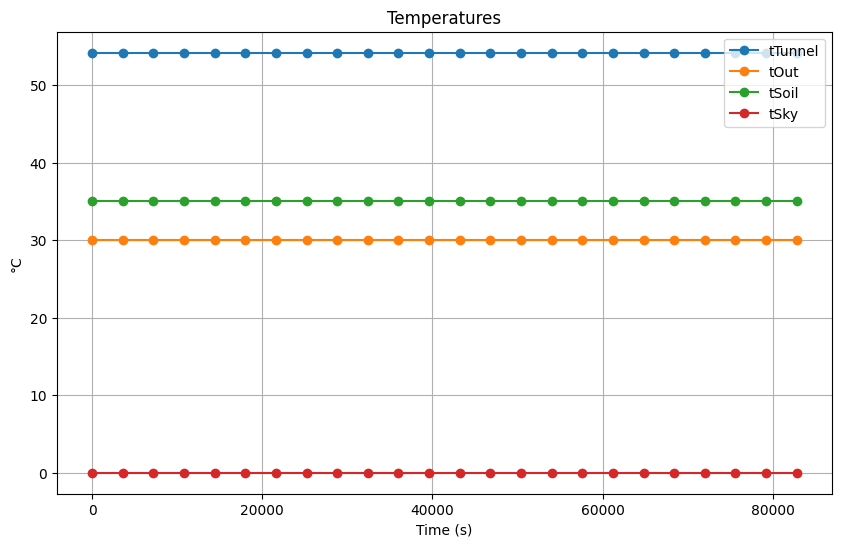

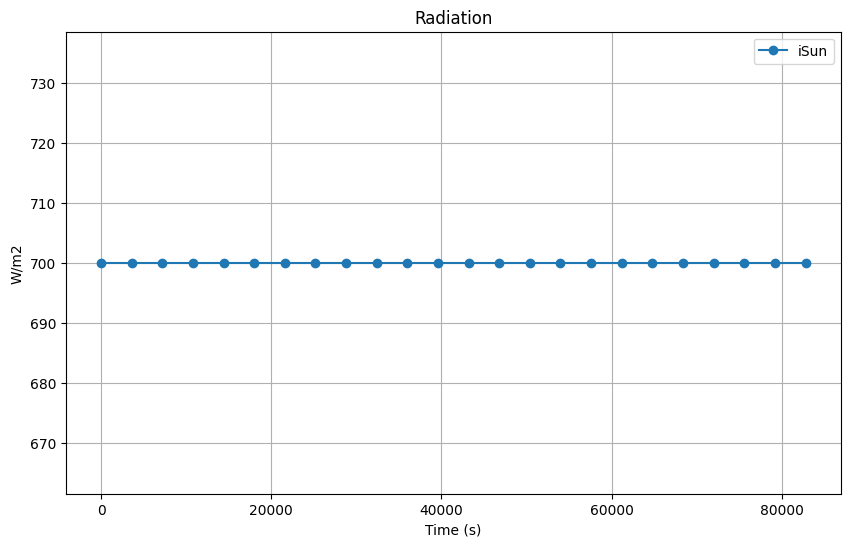

Variable,Definition
tau,0.7
iSun,700
fTunnelSky,0.5
epsCover,1
alphaR,6
tSky,0
tOut,30
tSoil,35
fTunnelSoil,0.5
epsSoil,1


In [9]:
"""
Make graphs
"""

def display_output(output_df, chosen_vars, titles, ylabels, line_style):
    for vars_to_plot, title, ylabel in zip(chosen_vars, titles, ylabels):
        plt.figure(figsize=(10, 6))
        
        for var in vars_to_plot:
            plt.plot(output_df["Time"], output_df[var], line_style, label=var)
        
        plt.xlabel("Time (s)")
        plt.ylabel(ylabel)
        plt.title(title)
        plt.legend()
        plt.grid(True)
        plt.show()

def model_table(mdl):
    display(pd.DataFrame(mdl.variables.items(), columns=["Variable", "Definition"])
            .style
                .hide(axis="index")
                .set_properties(**{"text-align": "left", "font-family": "monospace"})
                .set_table_styles([
                    {"selector": "th", "props": [("text-align", "left")]}
              ])
        )

display_output(output_df, [["tTunnel", "tOut",  "tSoil", "tSky"], ["iSun"]], ["Temperatures", "Radiation"], ["°C", "W/m2"], '-o')
model_table(mdl)

Explanation of the output above

## 3.8 Adding variable weather input

Explain what's happening here, also document where the weather data is coming from

In [13]:
# New model
options = {
    "options": {
        "t_start":"0",
        "t_end": str(16 * 24 * 60 * 60),
        "output_step": "300",
        "t_eval": "300"
    }
}

tunnel_def["dummy"] = {
        "description": "Dummy variable",
        "unit": "-",
        "reference": "Used to get the model going",
        "type": "state",
        "definition": "0",
        "init": "0"
    }

mdl_2 = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[tunnel_def, os.path.join("input", "example_weather.csv"), options], 
    output_path=os.path.join("output", "output_2.csv")
)
mdl_2.run()



Loading model from input\example_weather.csv
Simulation started at time (ISO format): 2026-08-04T13:06:57.166968
Running: 100.00%

Simulation complete at time (ISO format): 2026-08-04T13:06:57.218794
Simulated 15.996527777777779 days
Elapsed time: 0.051825761795043945 seconds
Output saved to file output\output_2.csv
Model structure log saved to output\output_2_model_struct_log.json
Simulation log saved to output\output_2_simulation_log.txt


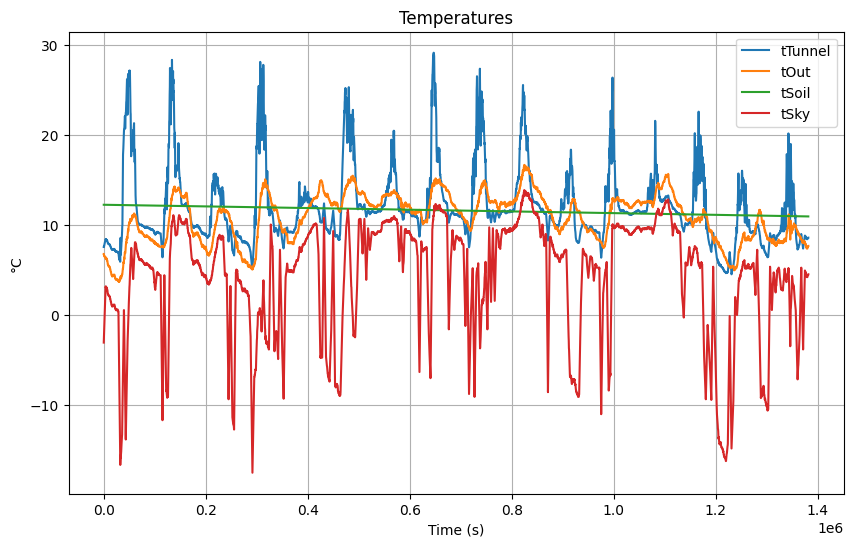

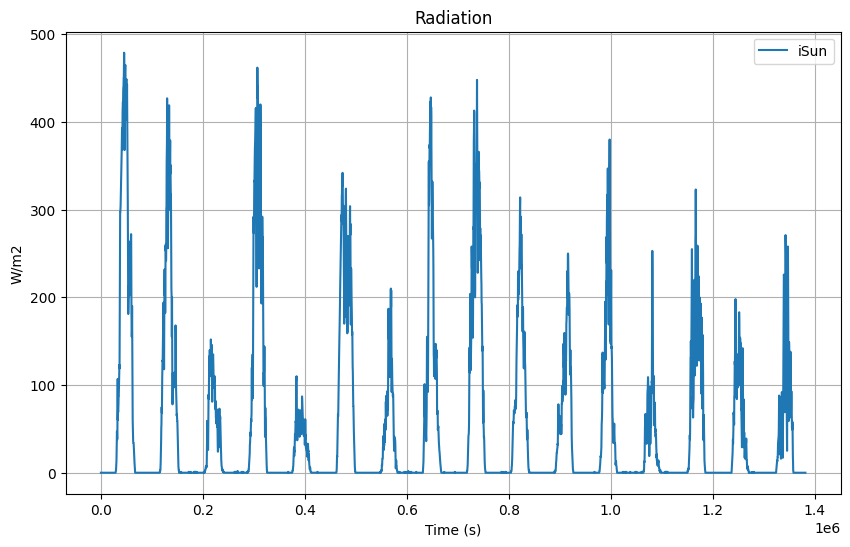

Variable,Definition
tau,0.7
iSun,iSun
fTunnelSky,0.5
epsCover,1
alphaR,6
tSky,tSky
tOut,tOut
tSoil,tSoil
fTunnelSoil,0.5
epsSoil,1


In [14]:
"""
Make graphs
"""

# Load simulation result
output_2 = pd.read_csv(os.path.join("output", "output_2.csv"), header=[0,1,2], low_memory=False)

display_output(output_2, [["tTunnel", "tOut",  "tSoil", "tSky"], ["iSun"]], ["Temperatures", "Radiation"], ["°C", "W/m2"], '-')
model_table(mdl_2)

Exercise - make a new weather file, modify it, run the sim with it

## Reflection

To do

## Next step

- Explain why this isn't good enough
- Save the def file for future use